In [5]:
import pandas as pd 
import numpy as np
import datetime         #Shows in my time zone COL.

BWR-185 AIR2
8b514244

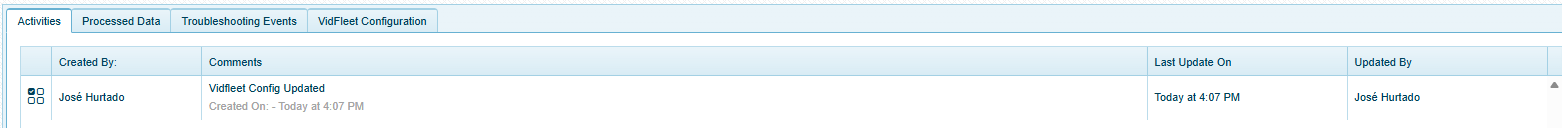
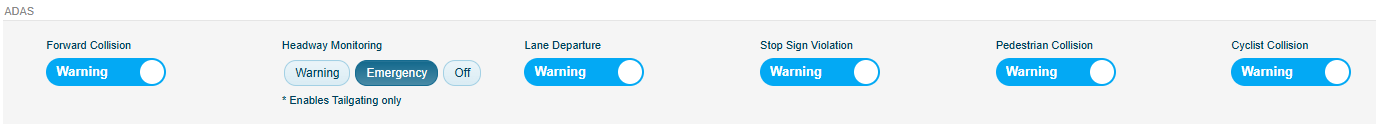

In [6]:
vf=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B514244.xlsx')
vf.info()

<class 'pandas.DataFrame'>
RangeIndex: 9267 entries, 0 to 9266
Columns: 296 entries, Message to Unnamed: 295
dtypes: float64(18), object(20), str(258)
memory usage: 20.9+ MB


In [7]:
vf['Message'].value_counts()

Message
{"notificationType":"TripInfo"              7014
{"notificationType":"CameraRunningInfo"     1148
{"notificationType":"AutoSnapshot"           804
{"notificationType":"IgnitionStatus"         242
{"notificationType":"CameraEvent"             27
{"notificationType":"PowerEvent"              22
{"notificationType":"ParkingHeartbeat"         9
{"notificationType":"MaintenanceWarning"       1
Name: count, dtype: int64

In [8]:
vf_camera_events=vf[vf['Message'].str.contains('CameraEvent')]
vf_camera_events['Unnamed: 4'].value_counts()

Unnamed: 4
event:"NO_SEATBELT"    18
event:"HARD_BRAKE"      6
event:"SHARP_TURN"      2
event:"HARD_ACCEL"      1
Name: count, dtype: int64

In [9]:
vf_camera_events['Unnamed: 5'].value_counts()

Unnamed: 5
eventCategory:"DMS"           18
eventCategory:"HARD_BRAKE"     6
eventCategory:"SHARP_TURN"     2
eventCategory:"HARD_ACCEL"     1
Name: count, dtype: int64

In [10]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot['Unnamed: 5']#.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\snapshot.csv')

5       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
27      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
38      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
49      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
60      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
                              ...                        
9241    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9244    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9252    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9255    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9264    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
Name: Unnamed: 5, Length: 804, dtype: str

In [11]:
vf_date_time=vf[vf['Unnamed: 3'].str.contains('time')]
vf_date_time['Unnamed: 3']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
print(vf_date_time.iloc[0,103])

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i])

nan
2026-09-30 19:03:29  ->  1790813009.0
2026-09-30 19:23:29  ->  1790814209.0
2026-09-30 19:33:29  ->  1790814809.0
2026-09-30 19:43:28  ->  1790815408.0
2026-09-30 19:53:28  ->  1790816008.0
2026-09-30 20:03:28  ->  1790816608.0
2026-09-30 20:23:28  ->  1790817808.0
2026-09-30 20:33:27  ->  1790818407.0
2026-09-30 20:43:27  ->  1790819007.0
2026-09-30 20:53:27  ->  1790819607.0
2026-09-30 21:03:27  ->  1790820207.0
2026-09-30 21:13:27  ->  1790820807.0
2026-09-30 21:19:36  ->  1790821176.0
2026-10-01 05:10:12  ->  1790849412.0
2026-10-01 05:20:12  ->  1790850012.0
2026-10-01 05:30:13  ->  1790850613.0
2026-10-01 05:35:00  ->  1790850900.0
2026-10-01 05:45:12  ->  1790851512.0
2026-10-01 06:05:12  ->  1790852712.0
2026-10-01 06:15:12  ->  1790853312.0
2026-10-01 06:25:12  ->  1790853912.0
2026-10-01 06:35:12  ->  1790854512.0
2026-10-01 06:45:12  ->  1790855112.0
2026-10-01 06:55:12  ->  1790855712.0
2026-10-01 07:05:12  ->  1790856312.0
2026-10-01 07:15:12  ->  1790856912.0
2026-10-

In [12]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot_date=[]
aux_date_time_as=[]
epoch_date_as=[]
vf_autosnapshot['Date']='NaN'

for i in range(0,vf_autosnapshot.shape[0]):
    aux_date_time_as.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date_as.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_autosnapshot.iloc[i,104]=str(epoch_date_as[i])

#vf_autosnapshot[['Unnamed: 5','Unnamed: 3','Date']].to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\autosnap_vck379.csv')       #Edit.

NO_SEATBELT


In [13]:
vf_no_seatbelt=vf[vf['Unnamed: 4'].str.contains('NO_SEATBELT')]
#vf_no_seatbelt

vf_date_time=vf_no_seatbelt[vf_no_seatbelt['Unnamed: 9'].str.contains('time')]
#vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))    
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-01 18:21:25  ->  1790896885.0  ->  speed:52.05231
2026-10-01 18:28:26  ->  1790897306.0  ->  speed:38.254913
2026-10-01 18:44:47  ->  1790898287.0  ->  speed:45.849964
2026-10-02 07:27:31  ->  1790944051.0  ->  speed:47.26304
2026-10-02 18:30:30  ->  1790983830.0  ->  speed:11.308312
2026-10-04 06:42:27  ->  1791114147.0  ->  speed:71.865005
2026-10-05 07:28:41  ->  1791203321.0  ->  speed:24.03896
2026-10-05 18:38:34  ->  1791243514.0  ->  speed:10.821235
2026-10-06 18:05:40  ->  1791327940.0  ->  speed:59.05287
2026-10-07 05:35:47  ->  1791369347.0  ->  speed:56.061893
2026-10-09 16:26:46  ->  1791581206.0  ->  speed:29.869057
2026-10-10 07:27:44  ->  1791635264.0  ->  speed:59.999245
2026-10-10 13:59:57  ->  1791658797.0  ->  speed:23.775976
2026-10-10 15:00:50  ->  1791662450.0  ->  speed:42.80898
2026-10-11 08:12:45  ->  1791724365.0  ->  speed:61.89384
2026-10-13 16:50:52  ->  1791928252.0  ->  speed:13.52886
2026-10-14 20:21:06  ->  1792027266.0  ->  speed:47.72604
2026-

USING_PHONE

In [14]:
using_phone=vf[vf['Unnamed: 4'].str.contains('USING_PHONE')]
#vf_no_seatbelt

vf_date_time=using_phone[using_phone['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

DROWSINESS

In [15]:
drowsiness=vf[vf['Unnamed: 4'].str.contains('DROWSINESS')]
#vf_no_seatbelt

vf_date_time=drowsiness[drowsiness['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

YAWN

In [16]:
yawn=vf[vf['Unnamed: 4'].str.contains('YAWN')]
#vf_no_seatbelt

vf_date_time=yawn[yawn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

SHARP_TURN

In [17]:
sharp_turn=vf[vf['Unnamed: 4'].str.contains('SHARP')]
#vf_no_seatbelt

vf_date_time=sharp_turn[sharp_turn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-03 15:02:52  ->  1791057772.0  ->  speed:47.14266
2026-10-04 19:58:56  ->  1791161936.0  ->  speed:37.486332


HARD_BRAKE

In [18]:
hard_brake=vf[vf['Unnamed: 4'].str.contains('HARD')]
#vf_no_seatbelt

vf_date_time=hard_brake[hard_brake['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-06 05:18:51  ->  1791281931.0  ->  time:1791281931000
2026-10-09 05:33:12  ->  1791541992.0  ->  time:1791541993000
2026-10-12 18:54:53  ->  1791849293.0  ->  speed:67.827644
2026-10-13 20:35:04  ->  1791941704.0  ->  time:1791941704000
2026-10-16 22:08:56  ->  1792206536.0  ->  time:1792206536000
2026-10-17 05:37:28  ->  1792233448.0  ->  time:1792233449000
2026-10-17 07:17:00  ->  1792239420.0  ->  time:1792239420000


STOP_SIGN_VIOLATION

In [19]:
hard_brake=vf[vf['Unnamed: 4'].str.contains('STOP_SIGN_VIOLATION')]
#vf_no_seatbelt

vf_date_time=hard_brake[hard_brake['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

In [20]:
vf_headway=vf[vf['Unnamed: 4'].str.contains('HEADWAY')]

vf_date_time=vf_headway[vf_headway['Unnamed: 10'].str.contains('time')]
#vf_date_time['Unnamed: 9']
headway_event=[]
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    headway_event.append(vf_date_time.iloc[i,5])
    aux_date_time.append(float(vf_date_time.iloc[i,10][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],headway_event[i])